# Hierarchical Bayesian Analysis of Regional Poverty Risk (Eurostat AROPE 2022)

This notebook compares a **pooled linear model (Model 1)** against a **partially pooled hierarchical model with country-specific intercepts and income slopes (Model 2)**, followed by PSIS-LOO model comparison and a prior sensitivity analysis.

**Workflow safeguards:**
- Raw CSV data is treated as **read-only**; all transformations occur in memory on `df = df_raw.copy()`.
- Prior specifications are stored in a central `PRIOR_SETS` dictionary for clean experimentation.
- Model fitting is separated from diagnostic and plotting cells so plots can be adjusted without re-running MCMC.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bambi as bmb
import arviz as az

os.makedirs("../data", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

In [2]:
# 1. Load Raw Data (Read-Only) & Transform in Memory
raw_data_paths = ["../data/eurostat_arope_2022.csv"]
data_path = next(p for p in raw_data_paths if os.path.exists(p))

df_raw = pd.read_csv(data_path)
df = df_raw.copy()  

# Log-transform and globally standardize population density from raw `pop_density`
log_pop = np.log(df["pop_density"])
df["log_pop_density_scaled"] = (log_pop - log_pop.mean()) / log_pop.std()
df["country"] = df["country"].astype("category")

print(
    f"Observations (N): {len(df)} | "
    f"Countries (J): {df['country'].nunique()} | "
    f"Missing values: {df.isnull().sum().sum()}"
)

summary_cols = [
    "arope_rate",
    "disposable_income",
    "pop_density",
    "arope_scaled",
    "disposable_income_scaled",
    "log_pop_density_scaled",
]
display(df[summary_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

Observations (N): 232 | Countries (J): 27 | Missing values: 0


,count,mean,std,min,50%,max
arope_rate,232.0,21.87,8.44,7.30,20.00,49.20
disposable_income,232.0,18981.90,6949.41,5400.00,21050.00,37700.00
pop_density,232.0,345.67,871.44,3.50,120.20,7660.00
arope_scaled,232.0,-0.00,1.00,-1.73,-0.22,3.24
disposable_income_scaled,232.0,0.00,1.00,-1.95,0.30,2.69
log_pop_density_scaled,232.0,0.00,1.00,-3.17,-0.13,3.44


## 2. Prior Specifications & Reusable Modeling Helpers

We define three prior regimes on standardized predictors and outcome:
1. **`baseline`**: Weakly informative $\text{Normal}(0, 0.5)$ slopes and $\text{HalfNormal}(0.5)$ group-level SDs.
2. **`wider_weakly_informative`**: Relaxes slope and group-level SD scales to $1.5$ to check whether tight baseline priors shrink large cross-country differences.
3. **`heavy_tail_student_t`**: Uses $\text{HalfStudentT}(\nu=4, \sigma=1.0)$ hyperpriors to accommodate outlier countries without over-shrinking group variances.

In [3]:
FORMULA_M1 = "arope_scaled ~ disposable_income_scaled + log_pop_density_scaled"
FORMULA_M2 = (
    "arope_scaled ~ disposable_income_scaled + log_pop_density_scaled "
    "+ (1 + disposable_income_scaled | country)"
)

POP_VARS = [
    "Intercept",
    "disposable_income_scaled",
    "log_pop_density_scaled",
    "1|country_sigma",
    "disposable_income_scaled|country_sigma",
    "sigma",
]

PRIOR_SETS = {
    "baseline": {
        "m1": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=0.5),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=0.5),
            "sigma": bmb.Prior("Exponential", lam=1),
        },
        "m2": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=0.5),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=0.5),
            "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.5)),
            "disposable_income_scaled|country": bmb.Prior(
                "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.5)
            ),
            "sigma": bmb.Prior("Exponential", lam=1),
        },
    },
    "wider_weakly_informative": {
        "m1": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
            "sigma": bmb.Prior("Exponential", lam=1),
        },
        "m2": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
            "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=1.5)),
            "disposable_income_scaled|country": bmb.Prior(
                "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=1.5)
            ),
            "sigma": bmb.Prior("Exponential", lam=1),
        },
    },
    "heavy_tail_student_t": {
        "m1": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
            "sigma": bmb.Prior("HalfStudentT", nu=4, sigma=1.0),
        },
        "m2": {
            "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
            "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
            "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
            "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfStudentT", nu=4, sigma=1.0)),
            "disposable_income_scaled|country": bmb.Prior(
                "Normal", mu=0, sigma=bmb.Prior("HalfStudentT", nu=4, sigma=1.0)
            ),
            "sigma": bmb.Prior("HalfStudentT", nu=4, sigma=1.0),
        },
    },
}


def check_convergence(idata, model_name):
    summary = az.summary(idata, round_to=3)
    max_rhat = summary["r_hat"].max()
    min_ess_bulk = summary["ess_bulk"].min()
    min_ess_tail = summary["ess_tail"].min()
    divergences = int(idata.sample_stats["diverging"].sum().item())

    print(f"--- {model_name} Convergence Diagnostics ---")
    print(f"Max R-hat:        {max_rhat:.4f}  (Target: <= 1.01)")
    print(f"Min Bulk-ESS:     {min_ess_bulk:.0f}    (Target: > 400)")
    print(f"Min Tail-ESS:     {min_ess_tail:.0f}    (Target: > 400)")
    print(f"Divergences:      {divergences}       (Target: 0)\n")
    return summary


def fit_models(df, prior_name="baseline", draws=2000, tune=1000, chains=4, seed=42, verbose=True):
    priors = PRIOR_SETS[prior_name]

    model_1 = bmb.Model(FORMULA_M1, data=df, family="gaussian", priors=priors["m1"])
    if verbose:
        print(f"=== Model 1 Specification ({prior_name}) ===")
        print(model_1)

    idata_1 = model_1.fit(
        draws=draws,
        tune=tune,
        chains=chains,
        target_accept=0.95,
        random_seed=seed,
        idata_kwargs={"log_likelihood": True},
    )

    model_2 = bmb.Model(FORMULA_M2, data=df, family="gaussian", priors=priors["m2"])
    if verbose:
        print(f"\n=== Model 2 Specification ({prior_name}) ===")
        print(model_2)

    idata_2 = model_2.fit(
        draws=draws,
        tune=tune,
        chains=chains,
        target_accept=0.95,
        random_seed=seed,
        idata_kwargs={"log_likelihood": True},
    )

    return model_1, idata_1, model_2, idata_2

## 3. Baseline Fit & MCMC Diagnostics (Model 1 vs. Model 2)

Fit both models under the `baseline` prior specification and verify $\hat{R}$, Bulk/Tail ESS, and divergent transitions.

In [4]:
ACTIVE_PRIOR = "baseline"

model_1, idata_1, model_2, idata_2 = fit_models(df, prior_name=ACTIVE_PRIOR, verbose=True)

summary_1 = check_convergence(idata_1, f"Model 1 (Pooled | {ACTIVE_PRIOR})")
summary_2 = check_convergence(idata_2, f"Model 2 (Hierarchical | {ACTIVE_PRIOR})")

=== Model 1 Specification (baseline) ===
       Formula: arope_scaled ~ disposable_income_scaled + log_pop_density_scaled
        Family: gaussian
          Link: mu = identity
  Observations: 232
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.0)
            disposable_income_scaled ~ Normal(mu: 0.0, sigma: 0.5)
            log_pop_density_scaled ~ Normal(mu: 0.0, sigma: 0.5)
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, disposable_income_scaled, log_pop_density_scaled]


/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 4 seconds.



=== Model 2 Specification (baseline) ===
       Formula: arope_scaled ~ disposable_income_scaled + log_pop_density_scaled + (1 + disposable_income_scaled | country)
        Family: gaussian
          Link: mu = identity
  Observations: 232
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.0)
            disposable_income_scaled ~ Normal(mu: 0.0, sigma: 0.5)
            log_pop_density_scaled ~ Normal(mu: 0.0, sigma: 0.5)
        
        Group-level effects
            1|country ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 0.5))
            disposable_income_scaled|country ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 0.5))
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, disposable_income_scaled, log_pop_density_scaled, 1|country_sigma, 1|country_offset, disposable_income_scaled|country_sigma, disposable_income_scaled|country_offset]


/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 22 seconds.


--- Model 1 (Pooled | baseline) Convergence Diagnostics ---
Max R-hat:        1.0010  (Target: <= 1.01)
Min Bulk-ESS:     8645    (Target: > 400)
Min Tail-ESS:     5106    (Target: > 400)
Divergences:      0       (Target: 0)

--- Model 2 (Hierarchical | baseline) Convergence Diagnostics ---
Max R-hat:        1.0020  (Target: <= 1.01)
Min Bulk-ESS:     2990    (Target: > 400)
Min Tail-ESS:     4137    (Target: > 400)
Divergences:      0       (Target: 0)



,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,-0.313,0.219,-0.668,0.027,3062.133,4136.847,1.001,0.004,0.003
disposable_income_scaled,-1.084,0.209,-1.415,-0.744,4302.081,4811.238,1.001,0.003,0.002
log_pop_density_scaled,0.196,0.048,0.120,0.273,10787.633,6273.277,1.000,0.000,0.000
1|country_sigma,0.966,0.177,0.705,1.260,2990.486,4406.602,1.001,0.003,0.002
disposable_income_scaled|country_sigma,0.674,0.141,0.467,0.914,4356.662,5375.752,1.001,0.002,0.001
sigma,0.549,0.029,0.505,0.597,7190.092,6022.967,1.000,0.000,0.000


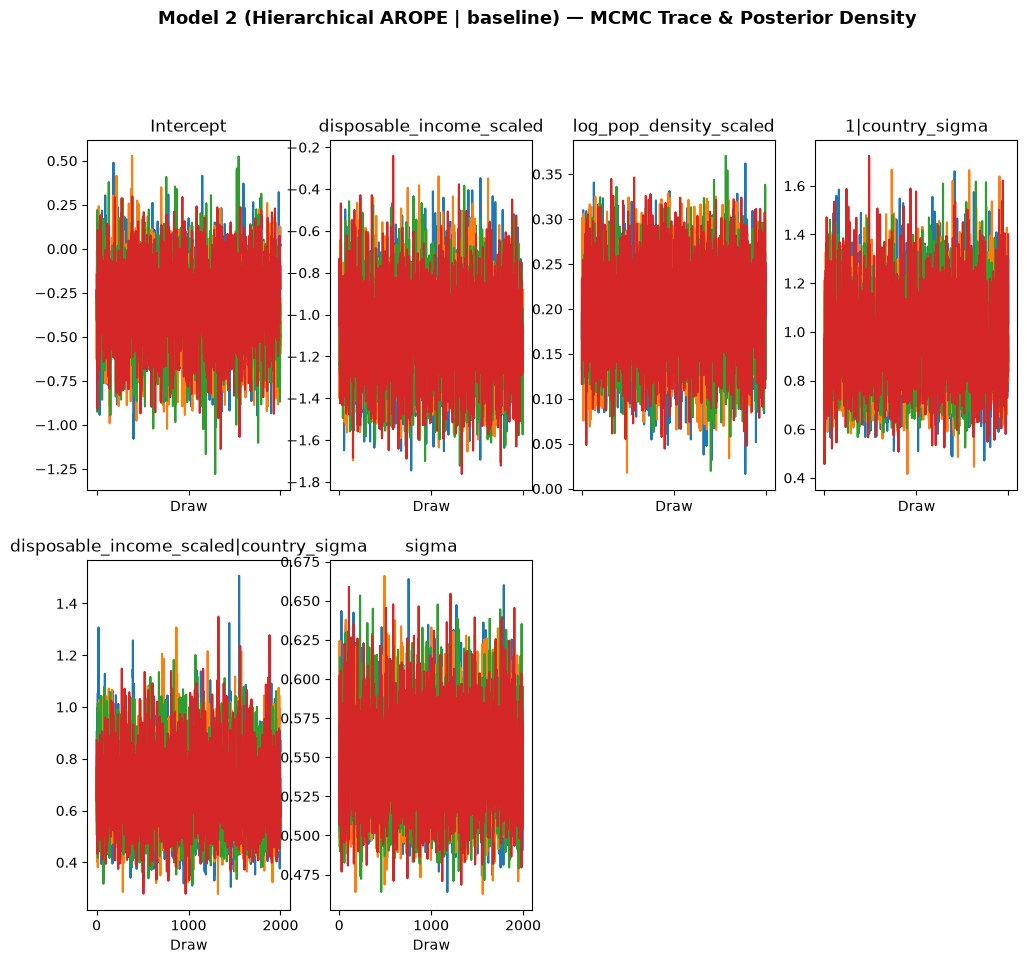

In [5]:
# Population-level posterior summary & trace diagnostics for Model 2
display(summary_2.loc[POP_VARS])

pc_trace = az.plot_trace(
    idata_2,
    var_names=POP_VARS,
    figure_kwargs={"figsize": (12, 10)},
)
fig_trace = pc_trace.viz["figure"].item() if hasattr(pc_trace, "viz") else plt.gcf()
fig_trace.suptitle(
    f"Model 2 (Hierarchical AROPE | {ACTIVE_PRIOR}) — MCMC Trace & Posterior Density",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
fig_trace.savefig(f"../figures/02_trace_diagnostics_{ACTIVE_PRIOR}.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Predictive Model Comparison (PSIS-LOO)

Compare out-of-sample expected log pointwise predictive density ($\text{ELPD}_{\text{LOO}}$) between the pooled and hierarchical models, and check Pareto-$k$ diagnostics for influential observations.

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Model 2 (Hierarchical),0,0.0,0.0,NaN,,8 k̂ > 0.70,34.7,-210.0,10.0,1.0
Model 1 (Pooled),1,-100.0,12.0,1.0,,,5.0,-320.0,12.0,0.0


/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Model 2 observations with Pareto k > 0.7: 8 / 232


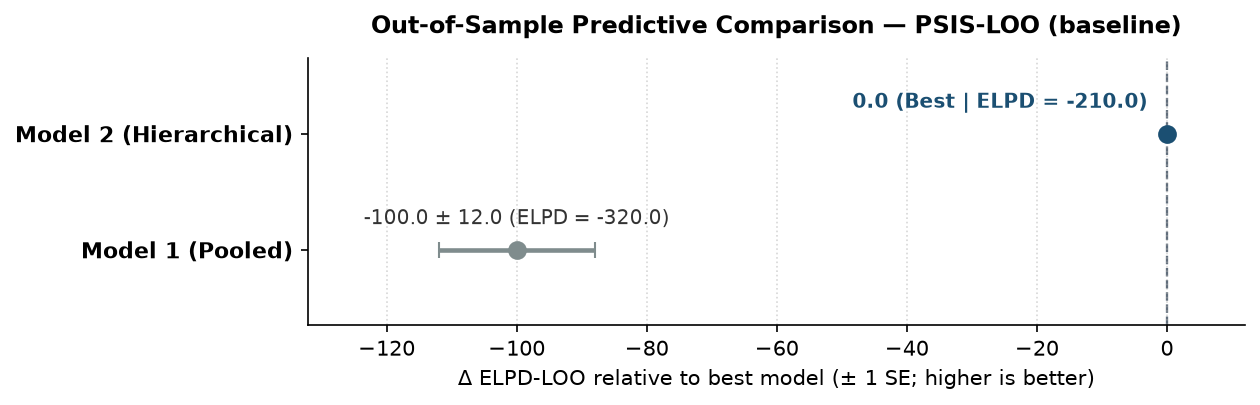

In [10]:
if "log_likelihood" not in idata_1:
    model_1.compute_log_likelihood(idata_1)
if "log_likelihood" not in idata_2:
    model_2.compute_log_likelihood(idata_2)

cmp = az.compare({"Model 1 (Pooled)": idata_1, "Model 2 (Hierarchical)": idata_2})
display(cmp)

loo_2 = az.loo(idata_2)
high_k = int(np.sum(loo_2.pareto_k.values > 0.7))
print(f"Model 2 observations with Pareto k > 0.7: {high_k} / {loo_2.pareto_k.size}")

# Publication-clean ELPD-LOO comparison plot
elpd_col = "elpd_loo" if "elpd_loo" in cmp.columns else "elpd"
fig, ax = plt.subplots(figsize=(8.5, 2.8), dpi=150)

y_pos = np.arange(len(cmp))
diffs = cmp["elpd_diff"].values
dses = cmp["dse"].values
colors = ["#1b4f72" if r == 0 else "#7f8c8d" for r in cmp["rank"]]

ax.axvline(0, color="#2c3e50", linestyle="--", linewidth=1.1, alpha=0.75, zorder=1)

for i, (diff, dse, c, name) in enumerate(zip(diffs, dses, colors, cmp.index)):
    elpd_val = cmp.loc[name, elpd_col]
    ax.errorbar(
        diff, i, xerr=dse, fmt="o", color=c, ecolor=c,
        elinewidth=2.2, capsize=4, markersize=8, zorder=3,
    )
    if diff == 0:
        label = f"0.0 (Best | ELPD = {elpd_val:.1f})"
        ax.text(diff - 3, i - 0.18, label, va="bottom", ha="right", fontsize=9.5, color="#1b4f72", fontweight="bold")
    else:
        label = f"{diff:.1f} ± {dse:.1f} (ELPD = {elpd_val:.1f})"
        ax.text(diff, i - 0.18, label, va="bottom", ha="center", fontsize=9.5, color="#333333")

ax.set_yticks(y_pos)
ax.set_yticklabels(cmp.index, fontsize=10.5, fontweight="bold")
ax.invert_yaxis()
ax.set_ylim(len(cmp) - 0.35, -0.65)
ax.set_xlim(min(diffs - dses) * 1.18, 12)
ax.set_xlabel("Δ ELPD-LOO relative to best model (± 1 SE; higher is better)", fontsize=10)
ax.set_title(f"Out-of-Sample Predictive Comparison — PSIS-LOO ({ACTIVE_PRIOR})", fontsize=11.5, fontweight="bold", pad=12)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(f"../figures/03_loo_compare_{ACTIVE_PRIOR}.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Country-Specific Intercepts & Income Slopes

Compute total country-level intercepts ($\beta_0 + u_{0j}$) and total country-level income slopes ($\beta_1 + u_{1j}$) from the posterior draws and visualize cross-country heterogeneity.

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
1|country[AT],0.673,0.625,-0.313,1.683,6444.176,5979.767,1.000,0.008,0.007
1|country[BE],1.420,0.445,0.721,2.155,5892.037,5607.125,1.000,0.006,0.005
1|country[BG],-0.573,0.731,-1.767,0.573,7454.043,5685.554,1.000,0.009,0.009
1|country[CY],-0.254,0.511,-1.067,0.555,9645.608,5838.389,1.001,0.005,0.006
1|country[CZ],-1.506,0.433,-2.197,-0.809,6453.206,6354.039,1.000,0.005,0.004
...,...,...,...,...,...,...,...,...,...
country_total_income_slope[PT],-0.889,0.572,-1.787,0.042,10082.867,6415.725,1.000,0.006,0.006
country_total_income_slope[RO],-1.764,0.360,-2.355,-1.199,8040.995,5659.293,1.001,0.004,0.004
country_total_income_slope[SE],-0.994,0.480,-1.750,-0.217,9690.852,6274.168,1.000,0.005,0.005
country_total_income_slope[SI],-0.833,0.686,-1.894,0.298,9690.364,6610.350,1.000,0.007,0.008


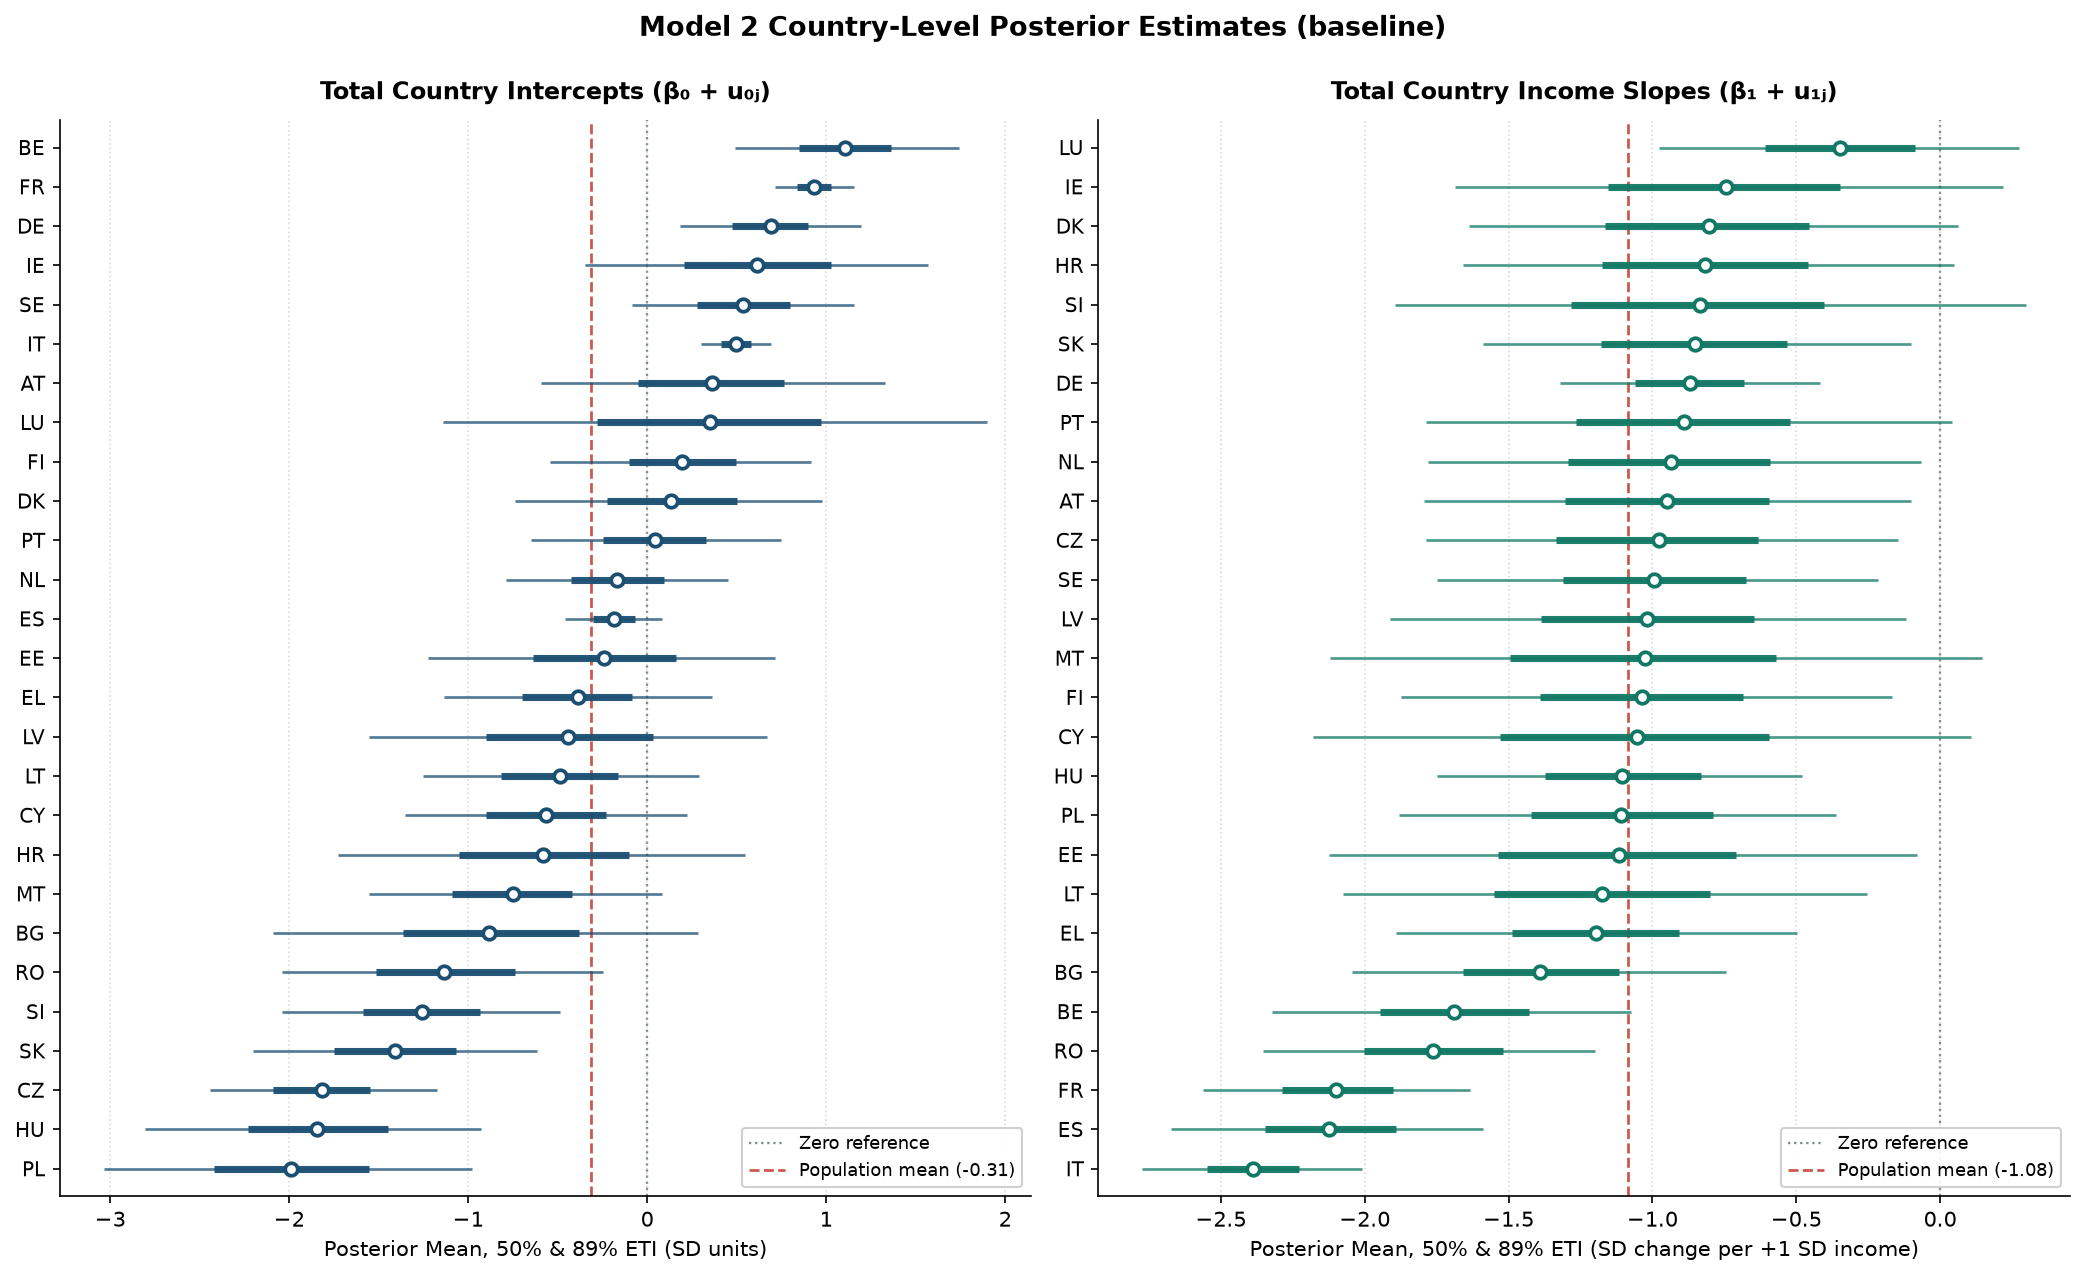

In [11]:
post = idata_2.posterior
post["country_total_intercept"] = post["Intercept"] + post["1|country"]
post["country_total_income_slope"] = (
    post["disposable_income_scaled"] + post["disposable_income_scaled|country"]
)

re_summary = az.summary(
    idata_2,
    var_names=[
        "1|country",
        "disposable_income_scaled|country",
        "country_total_intercept",
        "country_total_income_slope",
    ],
    round_to=3,
)
display(re_summary)


def plot_ranked_caterpillar(ax, da, pop_da, title, xlabel, color="#1b4f72"):
    group_dim = da.dims[-1]
    sample_dims = tuple(d for d in da.dims if d != group_dim)

    means = da.mean(dim=sample_dims).values
    q055, q25, q75, q945 = da.quantile([0.055, 0.25, 0.75, 0.945], dim=sample_dims).values
    labels = da.coords[group_dim].values.astype(str)

    # Sort countries from lowest to highest posterior mean
    order = np.argsort(means)
    labels = labels[order]
    means, q055, q25, q75, q945 = means[order], q055[order], q25[order], q75[order], q945[order]

    y = np.arange(len(labels))
    pop_mean = float(pop_da.mean())

    ax.axvline(0, color="#7f8c8d", linestyle=":", linewidth=1.1, zorder=1, label="Zero reference")
    ax.axvline(
        pop_mean, color="#c0392b", linestyle="--", linewidth=1.3, alpha=0.85, zorder=2,
        label=f"Population mean ({pop_mean:.2f})",
    )

    # 89% ETI (thin outer bar) and 50% IQR (thick inner bar)
    ax.hlines(y, q055, q945, color=color, linewidth=1.3, alpha=0.75, zorder=3)
    ax.hlines(y, q25, q75, color=color, linewidth=3.4, alpha=0.95, zorder=4)
    ax.scatter(means, y, color="white", edgecolor=color, s=36, linewidth=1.8, zorder=5)

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9.5)
    ax.set_ylim(-0.7, len(labels) - 0.3)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_title(title, fontsize=11.5, fontweight="bold", pad=10)
    ax.grid(axis="x", linestyle=":", alpha=0.45)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=True, framealpha=0.92, fontsize=8.5)


fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), dpi=150)

plot_ranked_caterpillar(
    axes[0],
    post["country_total_intercept"],
    post["Intercept"],
    "Total Country Intercepts (β₀ + u₀ⱼ)",
    "Posterior Mean, 50% & 89% ETI (SD units)",
    color="#1b4f72",
)

plot_ranked_caterpillar(
    axes[1],
    post["country_total_income_slope"],
    post["disposable_income_scaled"],
    "Total Country Income Slopes (β₁ + u₁ⱼ)",
    "Posterior Mean, 50% & 89% ETI (SD change per +1 SD income)",
    color="#117864",
)

fig.suptitle(
    f"Model 2 Country-Level Posterior Estimates ({ACTIVE_PRIOR})",
    fontsize=13,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
fig.savefig(f"../figures/04_country_effects_{ACTIVE_PRIOR}.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Prior Sensitivity Analysis

Evaluate whether posterior estimates and LOO predictive performance for Model 2 remain stable across `baseline`, `wider_weakly_informative`, and `heavy_tail_student_t` priors (reusing the already-fitted `baseline` chains).

In [9]:
sensitivity_runs = {
    ACTIVE_PRIOR: {"model_1": model_1, "idata_1": idata_1, "model_2": model_2, "idata_2": idata_2}
}

for prior_name in PRIOR_SETS:
    if prior_name in sensitivity_runs:
        continue
    print(f"Fitting prior set: {prior_name}...")
    m1, id1, m2, id2 = fit_models(df, prior_name=prior_name, verbose=False)
    check_convergence(id2, f"Model 2 ({prior_name})")
    sensitivity_runs[prior_name] = {"model_1": m1, "idata_1": id1, "model_2": m2, "idata_2": id2}

# Compare Model 2 population parameter posteriors across prior sets
tables = {}
for name, res in sensitivity_runs.items():
    s = az.summary(res["idata_2"], var_names=POP_VARS, round_to=3)
    keep_cols = [c for c in ["mean", "sd", "eti89_lb", "eti89_ub", "hdi_3%", "hdi_97%", "r_hat"] if c in s.columns]
    tables[name] = s[keep_cols]

prior_comparison = pd.concat(tables, axis=1)
display(prior_comparison)

# Compare Model 2 predictive accuracy across prior sets
loo_prior_cmp = az.compare({name: res["idata_2"] for name, res in sensitivity_runs.items()})
display(loo_prior_cmp)

Fitting prior set: wider_weakly_informative...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, disposable_income_scaled, log_pop_density_scaled]


/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 5 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, disposable_income_scaled, log_pop_density_scaled, 1|country_sigma, 1|country_offset, disposable_income_scaled|country_sigma, disposable_income_scaled|country_offset]


/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 24 seconds.


... (6 outputs left out)

--- Model 2 (heavy_tail_student_t) Convergence Diagnostics ---
Max R-hat:        1.0030  (Target: <= 1.01)
Min Bulk-ESS:     1987    (Target: > 400)
Min Tail-ESS:     2900    (Target: > 400)
Divergences:      0       (Target: 0)



baseline                           \
                                           mean     sd eti89_lb eti89_ub   
Intercept                                -0.313  0.219   -0.668    0.027   
disposable_income_scaled                 -1.084  0.209   -1.415   -0.744   
log_pop_density_scaled                    0.196  0.048    0.120    0.273   
1|country_sigma                           0.966  0.177    0.705    1.260   
disposable_income_scaled|country_sigma    0.674  0.141    0.467    0.914   
sigma                                     0.549  0.029    0.505    0.597   

                                              wider_weakly_informative         \
                                        r_hat                     mean     sd   
Intercept                               1.001                   -0.369  0.264   
disposable_income_scaled                1.001                   -1.358  0.235   
log_pop_density_scaled                  1.000                    0.221  0.048   
1|country_sigma                         1.001                    1.239  0.260   
disposable_income_scaled|country_sigma  1.001                    0.674  0.166   
sigma                                   1.000                    0.540  0.028   

                                                                 \
                                       eti89_lb eti89_ub  r_hat   
Intercept                                -0.803    0.038  1.002   
disposable_income_scaled                 -1.726   -0.979  1.001   
log_pop_density_scaled                    0.145    0.297  1.001   
1|country_sigma                           0.868    1.691  1.001   
disposable_income_scaled|country_sigma    0.436    0.954  1.001   
sigma                                     0.497    0.587  1.000   

                                       heavy_tail_student_t                  \
                                                       mean     sd eti89_lb   
Intercept                                            -0.366  0.260   -0.782   
disposable_income_scaled                             -1.311  0.231   -1.678   
log_pop_density_scaled                                0.217  0.047    0.141   
1|country_sigma                                       1.184  0.244    0.835   
disposable_income_scaled|country_sigma                0.678  0.161    0.446   
sigma                                                 0.542  0.029    0.498   

                                                        
                                       eti89_ub  r_hat  
Intercept                                 0.042  1.001  
disposable_income_scaled                 -0.942  1.002  
log_pop_density_scaled                    0.292  1.000  
1|country_sigma                           1.609  1.003  
disposable_income_scaled|country_sigma    0.952  1.002  
sigma                                     0.589  1.000

/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/guille/Master/Aalto/BDA/eu-housing-hierarchical-bayes/venv/lib/python3.12/site-packages/arviz_stats/loo/loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly i

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
heavy_tail_student_t,0,0.0,0.00,NaN,,4 k̂ > 0.70,34.8,-210.0,10.0,1.0
wider_weakly_informative,1,-0.0,0.79,0.73,|elpd_diff| < 4,7 k̂ > 0.70,35.9,-210.0,11.0,0.0
baseline,2,-3.0,1.20,1.00,|elpd_diff| < 4,8 k̂ > 0.70,34.7,-210.0,10.0,0.0
